# 04 — Transfer learning with MobileNetV2

A MobileNetV2 pretrained on ImageNet is trained in two phases (frozen backbone, then partial fine-tuning) on the full dataset with seed 42.
It is compared with the CNN trained from scratch in 03_improvements.ipynb.

In [1]:
import os
import time
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
import sklearn
import tensorflow as tf
import keras
from utils import CACHE, METRICS, class_weights, evaluate, load_images, plot_curves

T0 = time.time()
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise SystemExit("No GPU found by TensorFlow: check the kernel and the CUDA libraries (see README) before running this notebook.")
tf.config.experimental.set_memory_growth(gpus[0], True)
print("GPU:", gpus)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| Pillow", PIL.__version__)

REPORTS, MODELS = Path("reports"), Path("models")
CACHE.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)
SEED, SIZE, BATCH, EPOCHS_1, EPOCHS_2, NOISE = 42, 128, 32, 10, 10, 0.03

I0000 00:00:1791532020.757861   60650 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791532021.549208   60650 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026100504 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Pillow 12.3.0


In [2]:
manifest = pd.read_csv("protocol/manifest.csv")
df = manifest[manifest["drop_reason"].isna()].reset_index(drop=True)
print(pd.crosstab(df["origin"], df["split"], margins=True, margins_name="total")[["train", "val", "test", "total"]])

splits = {s: df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
X = {s: load_images(d, SIZE) for s, d in splits.items()}
y = {s: d["label"].to_numpy() for s, d in splits.items()}
for s in X:
    print(s, X[s].shape, X[s].dtype)

cw = class_weights(y["train"])
sw_val = np.where(y["val"] == 1, cw[1], cw[0])
print("class weights:", {k: round(v, 3) for k, v in cw.items()})

split       train   val  test  total
origin                              
Painting     6997  1499  1500   9996
Photo        6995  1499  1499   9993
Schematics   6236  1336  1336   8908
Sketch        984   211   211   1406
Text         6999  1500  1500   9999
total       28211  6045  6046  40302


train (28211, 128, 128, 3) uint8
val (6045, 128, 128, 3) uint8
test (6046, 128, 128, 3) uint8
class weights: {0: 0.665, 1: 2.017}


Images stay uint8 0-255 and are rescaled to [-1, 1] inside the model by MobileNetV2's own preprocess_input, as the ImageNet weights expect.
The head is Dropout(0.2) and a sigmoid unit on the 1280 pooled features.
If the ImageNet weights cannot be downloaded, the cell stops with the error instead of using random weights.

In [3]:
keras.utils.set_random_seed(SEED)
try:
    backbone = keras.applications.MobileNetV2(input_shape=(SIZE, SIZE, 3), include_top=False, weights="imagenet", pooling="avg")
except Exception as e:
    print(f"ImageNet weights could not be loaded: {type(e).__name__}: {e}")
    raise

backbone.trainable = False
inputs = keras.Input((SIZE, SIZE, 3))
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = backbone(x, training=False)
x = keras.layers.Dropout(0.2)(x)
outputs = keras.layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs, name="mobilenetv2_transfer")

def compile_model(lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])

def n_params(m):
    trainable = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    return trainable, m.count_params()

compile_model(1e-3)
trainable, total = n_params(model)
print(f"Phase 1: total {total:,} | trainable {trainable:,} | frozen {total - trainable:,}")

Phase 1: total 2,259,265 | trainable 1,281 | frozen 2,257,984


Frozen means trainable=False: the backbone weights get no gradient update, and training=False keeps its BatchNorm layers in inference mode, so its outputs are fixed features.
Only the Dense(1) head (1,281 weights) is learned, on top of those features.

In [4]:
def score(tag):
    val = evaluate(y["val"], model.predict(X["val"], verbose=0), splits["val"]["origin"])
    train_acc = ((model.predict(X["train"], verbose=0).ravel() >= 0.5) == y["train"]).mean()
    tr, tot = n_params(model)
    return {"model": tag, "trainable params": tr, "total params": tot, "train accuracy": train_acc,
            "validation accuracy": val["accuracy"], "gap": train_acc - val["accuracy"],
            "val balanced accuracy": val["balanced_acc"], "val F1 Photo": val["f1"]}

t = time.time()
h1 = model.fit(X["train"], y["train"], validation_data=(X["val"], y["val"], sw_val), epochs=EPOCHS_1,
               batch_size=BATCH, class_weight=cw, verbose=0)
print(f"Phase 1: {time.time() - t:.0f} s")
rows = [score("phase 1: frozen backbone")]
weights_1 = model.get_weights()
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rows[0].items()})

Phase 1: 95 s


{'model': 'phase 1: frozen backbone', 'trainable params': 1281, 'total params': 2259265, 'train accuracy': np.float64(0.9772), 'validation accuracy': np.float64(0.9651), 'gap': np.float64(0.0121), 'val balanced accuracy': 0.9605, 'val F1 Photo': np.float64(0.9311)}


The last 30 layers of the backbone are unfrozen; BatchNorm layers stay frozen so their statistics are not disturbed by batches of 32.
The learning rate drops to 1e-5 because pretrained weights are already good, and large steps would quickly erase what they learned.

In [5]:
backbone.trainable = True
for layer in backbone.layers[:-30]:
    layer.trainable = False
for layer in backbone.layers[-30:]:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
compile_model(1e-5)  # recompile so the new trainable flags apply
trainable, total = n_params(model)
print(f"Phase 2: total {total:,} | trainable {trainable:,}")

t = time.time()
h2 = model.fit(X["train"], y["train"], validation_data=(X["val"], y["val"], sw_val), epochs=EPOCHS_1 + EPOCHS_2,
               initial_epoch=EPOCHS_1, batch_size=BATCH, class_weight=cw, verbose=0)
print(f"Phase 2: {time.time() - t:.0f} s")
rows.append(score("phase 2: fine-tuned"))
history = {k: h1.history[k] + h2.history[k] for k in h1.history}

Phase 2: total 2,259,265 | trainable 1,512,001


Phase 2: 92 s


The model kept for the test set is the end of phase 1 or of phase 2, whichever has the higher validation balanced accuracy; the test set plays no part in this choice.

In [6]:
summary = pd.DataFrame(rows).set_index("model")
summary.index.name = "model"
best = summary["val balanced accuracy"].idxmax()
phase2_gain = summary.loc[rows[1]["model"], "val balanced accuracy"] - summary.loc[rows[0]["model"], "val balanced accuracy"]
if best == rows[0]["model"]:
    model.set_weights(weights_1)
summary.to_csv(REPORTS / "04_summary_val.csv")
display(summary.astype(float).round(4))
print(f"Selected: {best} | phase 2 minus phase 1 on validation balanced accuracy: {100 * phase2_gain:+.2f} points (noise threshold {100 * NOISE:.0f})")

,trainable params,total params,train accuracy,validation accuracy,gap,val balanced accuracy,val F1 Photo
model,,,,,,,
phase 1: frozen backbone,1281.0,2259265.0,0.9772,0.9651,0.0121,0.9605,0.9311
phase 2: fine-tuned,1512001.0,2259265.0,1.0000,0.9821,0.0178,0.9763,0.9640


Selected: phase 2: fine-tuned | phase 2 minus phase 1 on validation balanced accuracy: +1.58 points (noise threshold 3)


What I observe

Observed:
- Fine-tuning adds 1.6 points of validation balanced accuracy, below the 3-point noise threshold.
- Train accuracy reaches 1.00 after fine-tuning.

Meaning: the frozen ImageNet features probably already carry most of the signal; the fine-tuning gain is not conclusive.

What I observe

Observed:
- The train-validation gap is 0.01 with the frozen backbone and 0.02 after fine-tuning.

Meaning: variance seems low in both phases, and the high train accuracy suggests low bias; this contrasts with the from-scratch CNN, whose gap was larger in 03.

Losses are class-weighted on both sides and comparable; accuracies are plain. The dashed line marks the start of fine-tuning.

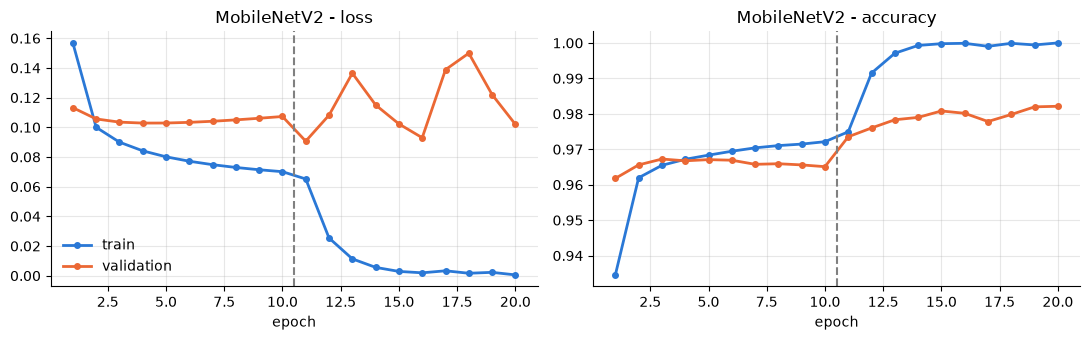

In [7]:
axes = plot_curves(history, "MobileNetV2")
for ax in axes:
    ax.axvline(EPOCHS_1 + 0.5, color="grey", ls="--")
plt.tight_layout()
plt.savefig(REPORTS / "04_curves.png", dpi=120)
plt.show()

## Test set

Test metrics are computed once here, at threshold 0.5, for the selected pretrained model only.
The other rows are read from reports/03_test_results.csv, not recomputed; a missing row is reported below.

In [8]:
test = evaluate(y["test"], model.predict(X["test"], verbose=0), splits["test"]["origin"])
ref = pd.read_csv(REPORTS / "03_test_results.csv", index_col="model")
wanted = {"majority": "majority", "decision_tree_meta": "decision tree (metadata)", "mlp (seed 42)": "MLP",
          "baseline CNN (this run)": "CNN baseline (03)", "final CNN (d. augmentation)": "CNN final, augmentation (03)"}
missing = [w for w in wanted if w not in ref.index]
if missing:
    print("Rows missing from reports/03_test_results.csv:", missing)
table = ref.loc[[w for w in wanted if w in ref.index]].rename(index=wanted)
table.loc["pretrained MobileNetV2"] = {m: test[m] for m in ref.columns}
table.index.name = "model"
table = table.astype(float).round(4)
table.to_csv(REPORTS / "04_test_results.csv")
print("Test set, full scope (n = %d), selected model: %s" % (len(y["test"]), best))
display(table)

Rows missing from reports/03_test_results.csv: ['majority']
Test set, full scope (n = 6046), selected model: phase 2: fine-tuned


,precision,recall,f1,balanced_acc,pr_auc,accuracy
model,,,,,,
decision tree (metadata),0.9641,0.9853,0.9746,0.9866,0.9849,0.9873
MLP,0.5099,0.9093,0.6534,0.8106,0.6152,0.7608
CNN baseline (03),0.7698,0.7698,0.7698,0.8470,0.8318,0.8859
"CNN final, augmentation (03)",0.7070,0.9079,0.7950,0.8920,0.8862,0.8839
pretrained MobileNetV2,0.9642,0.9713,0.9678,0.9797,0.9926,0.9840


What I observe

Observed:
- Test balanced accuracy is 0.98 for the pretrained model, against 0.89 for the best from-scratch CNN.
- It is close to the metadata tree.

Meaning: ImageNet features probably transfer well to this task, though ImageNet's many photos may favour the model; one seed.

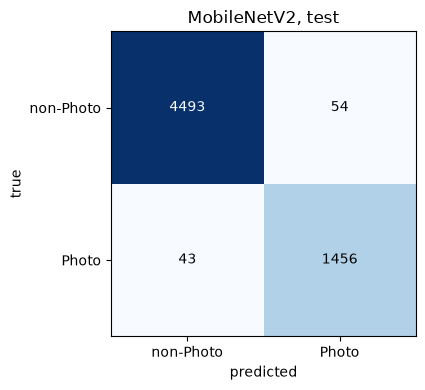

            CNN final (03)  pretrained
origin                                
Painting            0.3300      0.0333
Photo               0.0921      0.0287
Schematics          0.0516      0.0030
Sketch              0.0000      0.0000
Text                0.0000      0.0000


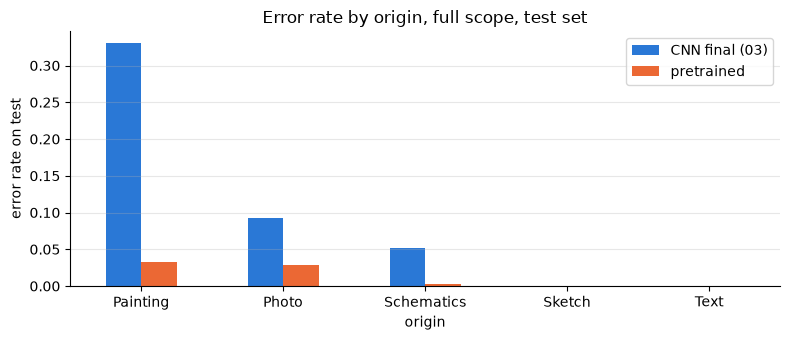

In [9]:
cm = test["cm"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["non-Photo", "Photo"])
ax.set_yticks([0, 1], ["non-Photo", "Photo"])
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("MobileNetV2, test")
plt.tight_layout()
plt.savefig(REPORTS / "04_confusion.png", dpi=120)
plt.show()

err03 = pd.read_csv(REPORTS / "03_error_by_origin.csv", index_col="origin")
err = pd.DataFrame({"CNN final (03)": err03["d. augmentation"], "pretrained": test["error_by_origin"]})
err.index.name = "origin"
err.round(4).to_csv(REPORTS / "04_error_by_origin.csv")
print(err.round(4))
ax = err.plot.bar(figsize=(8, 3.5), color=["#2a78d6", "#eb6834"], rot=0)
ax.set_ylabel("error rate on test")
ax.set_title("Error rate by origin, full scope, test set")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS / "04_error_by_origin.png", dpi=120)
plt.show()

What I observe

Observed:
- Painting error falls from 0.33 (CNN from scratch) to 0.03.
- Photo error also falls.

Meaning: pretrained features probably separate paintings from photos much better; this notebook does not test why.

Saved models/pretrained_model.keras


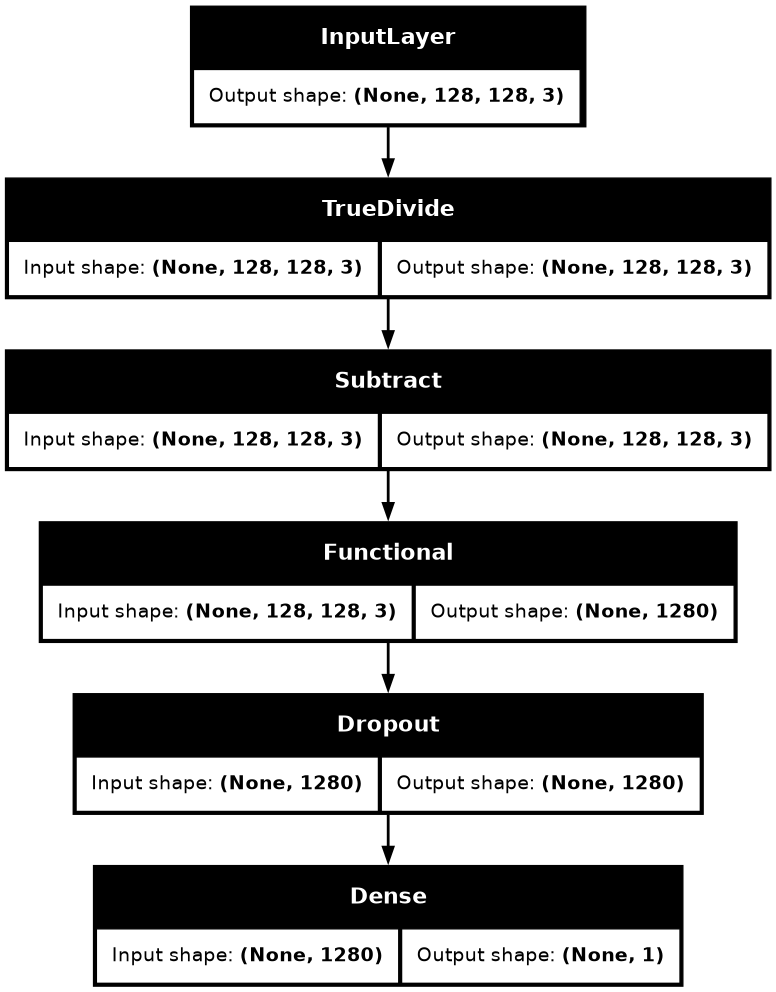

In [10]:
keras.utils.plot_model(model, to_file=str(REPORTS / "04_pretrained_architecture.png"), show_shapes=True, expand_nested=False, dpi=100)
model.save(MODELS / "pretrained_model.keras")
print("Saved", MODELS / "pretrained_model.keras")
from IPython.display import Image
Image(str(REPORTS / "04_pretrained_architecture.png"))

## Limits

ImageNet contains many photos, which may favour this model.
One seed (42) only: differences under 3 points of balanced accuracy are not conclusive.
Images are resized to 128x128 without keeping the aspect ratio, and the metadata tree reaches 0.9866 balanced accuracy, so format and resolution cues may explain part of the scores.
The ImageNet weights are downloaded on first run, so internet is needed once.

In [11]:
print(f"Total notebook runtime: {(time.time() - T0) / 60:.1f} min")

Total notebook runtime: 3.7 min
